# Giorno 3, pomeriggio: SciPy e statistica per il laboratorio

Obiettivo: una retta di taratura fatta come si deve, con le incertezze sui parametri e gli
intervalli di confidenza e di predizione, e un fit non lineare di cui sapete dire quanto
fidarvi. Poi t-test, ANOVA e cosa significa davvero un p-value.

È la parte più vicina al vostro lavoro quotidiano. Queste cose le conoscete già: oggi
imparate a scriverle in Python, e a non fidarvi di un R² da solo.

## 0. Cella di avvio

In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

def trova_dati():
    for cand in [Path("../dati"), Path("dati"), Path("corso_python_CNR/dati")]:
        if cand.exists():
            return cand
    for radice in [Path(".."), Path("."), Path("corso_python_CNR")]:
        if (radice / "genera_dati.py").exists():
            sys.path.insert(0, str(radice.resolve()))
            from genera_dati import genera_tutto
            return genera_tutto(radice / "dati")
    raise FileNotFoundError("Cartella 'dati' non trovata: carica la cartella del corso.")

DATI = trova_dati()
mpl.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
tar = pd.read_csv(DATI / "taratura.csv")
print(tar.groupby("conc_uM")["i_uA"].agg(["mean", "std"]).round(3))

---
## 1. Regressione lineare: pendenza, intercetta e le loro incertezze

`np.polyfit` dà i coefficienti; `scipy.stats.linregress` dà anche gli **errori standard**,
che sono quello che serve in un articolo. La regressione si fa sui punti singoli (18 misure),
non sulle medie per livello: le repliche portano informazione sulla dispersione.

In [ ]:
x = tar["conc_uM"].to_numpy()
y = tar["i_uA"].to_numpy()
n = len(x)

reg = stats.linregress(x, y)
print(f"pendenza   m = {reg.slope:.4f} ± {reg.stderr:.4f} µA/µM")
print(f"intercetta q = {reg.intercept:.4f} ± {reg.intercept_stderr:.4f} µA")
print(f"R² = {reg.rvalue**2:.5f}")

L'errore standard è "± una deviazione standard" sul parametro. Per un intervallo di
confidenza al 95 % si moltiplica per il quantile della t di Student con $n-2$ gradi di
libertà (≈ 2.1 con 16 gradi; tende a 1.96 per $n$ grande).

In [ ]:
gdl = n - 2
t95 = stats.t.ppf(0.975, gdl)
print(f"t(0.975, {gdl}) = {t95:.3f}")
print(f"m = {reg.slope:.4f}  IC95 % [{reg.slope - t95*reg.stderr:.4f}, {reg.slope + t95*reg.stderr:.4f}]")
print(f"q = {reg.intercept:.4f}  IC95 % [{reg.intercept - t95*reg.intercept_stderr:.4f}, {reg.intercept + t95*reg.intercept_stderr:.4f}]")
print("l'intercetta è compatibile con zero?", "no" if abs(reg.intercept) > t95 * reg.intercept_stderr else "sì")

### R² e cosa non dice

R² misura quanta varianza di $y$ è spiegata dalla retta. Non dice se la retta è il modello
giusto. Quattro insiemi di dati con la stessa retta e lo stesso R² = 0.67 (il quartetto di
Anscombe, 1973):

In [ ]:
A = {  # il quartetto di Anscombe
    "I":   ([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5], [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II":  ([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5], [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III": ([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5], [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV":  ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
fig, axs = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True, constrained_layout=True)
for ax, (k, (xa, ya)) in zip(axs, A.items()):
    r = stats.linregress(xa, ya)
    xx = np.linspace(3, 20, 10)
    ax.plot(xa, ya, "o", ms=4); ax.plot(xx, r.slope * xx + r.intercept, "-", color="crimson")
    ax.set_title(f"{k}: R² = {r.rvalue**2:.2f}, m = {r.slope:.2f}", fontsize=9)
plt.show()

Solo il primo è una regressione lineare sensata. Il secondo è curvo, il terzo ha un
anomalo, il quarto si regge su un solo punto. Nessuno di questi difetti si vede dall'R²:
si vedono dal grafico e dai residui (§ 4).

---
## 2. Retta di taratura: intervalli di confidenza e di predizione

Attorno alla retta si disegnano due bande diverse, e vanno tenute distinte:

- **Banda di confidenza**: dove sta la retta vera (la media di $y$ a ogni $x$) con il 95 % di
  probabilità. Si stringe con più punti.
- **Banda di predizione**: dove cadrà una nuova singola misura. È più larga, e non si stringe
  sotto la dispersione delle repliche.

Per una retta $\hat y = mx + q$, con $s_{y/x}$ = deviazione standard dei residui:

$$\text{conf}(x_0) = t \cdot s_{y/x}\sqrt{\frac{1}{n} + \frac{(x_0-\bar x)^2}{S_{xx}}}
\qquad
\text{pred}(x_0) = t \cdot s_{y/x}\sqrt{1 + \frac{1}{n} + \frac{(x_0-\bar x)^2}{S_{xx}}}$$

La sensibilità del metodo è la pendenza $m$: quanto segnale per unità di concentrazione.

In [ ]:
def bande_retta(x, y, x0, alpha=0.05):
    """Retta di regressione e semi-ampiezze delle bande di confidenza e predizione in x0."""
    reg = stats.linregress(x, y)
    n = len(x)
    y_hat = reg.slope * x + reg.intercept
    s_yx = np.sqrt(np.sum((y - y_hat) ** 2) / (n - 2))       # sd dei residui
    Sxx = np.sum((x - x.mean()) ** 2)
    t = stats.t.ppf(1 - alpha / 2, n - 2)
    termine = 1 / n + (x0 - x.mean()) ** 2 / Sxx
    conf = t * s_yx * np.sqrt(termine)
    pred = t * s_yx * np.sqrt(1 + termine)
    return reg, s_yx, reg.slope * x0 + reg.intercept, conf, pred

x0 = np.linspace(0, 52, 200)
reg, s_yx, y0, conf, pred = bande_retta(x, y, x0)
print(f"s(y/x) = {s_yx:.4f} µA   sensibilità = {reg.slope:.4f} µA/µM")

fig, ax = plt.subplots(figsize=(6, 4))
ax.fill_between(x0, y0 - pred, y0 + pred, alpha=0.12, lw=0, color="#0072B2", label="predizione 95 %")
ax.fill_between(x0, y0 - conf, y0 + conf, alpha=0.3, lw=0, color="#0072B2", label="confidenza 95 %")
ax.plot(x0, y0, "-", color="#0072B2", label="regressione")
ax.plot(x, y, "o", ms=4, color="black", label="misure")
ax.set_xlabel("concentrazione / µM"); ax.set_ylabel("i$_p$ / µA"); ax.legend(loc="upper left", frameon=False)
plt.show()

### E le metriche del vostro settore?

Ogni disciplina ricava dalla retta (o dalla curva) le sue grandezze derivate: limite di
rilevabilità e di quantificazione, concentrazione di un incognito, $x_{50}$ di una curva a
sigmoide, costanti di velocità. Sono tutte funzioni dei parametri appena stimati e delle loro
incertezze ($m$, $q$, $s_{y/x}$, errori standard). Quando sapete ottenere questi numeri con le
incertezze, le formule specifiche si prendono dalla linea guida del vostro settore e si
scrivono in due righe di codice, dichiarando sempre quale formula avete usato.

### Esercizio 6.1 (E3.1): un report di regressione completo, e un anomalo nascosto (livello 3)

Mettete insieme tutto in una funzione `report_regressione(x, y, nome)` che stampa un rapporto
e restituisce un dizionario con: `m`, `sm`, `q`, `sq` (errori standard), `ic_m`, `ic_q`
(semi-ampiezze degli IC al 95 %), `r2`, `s_yx`, `n`. Poi una seconda funzione per la figura:
punti, retta, bande di confidenza e di predizione (riusate `bande_retta`), equazione e R² nel riquadro.

Usatela due volte: sui dati originali e su una copia `tar_err` in cui una sola replica a 20 µM
è sbagliata del 30 % (già preparata nella cella). Domande, da rispondere in un commento:
quanto cambiano pendenza, $s_{y/x}$ e la semi-ampiezza della banda di predizione a 20 µM?
L'R² vi avverte che qualcosa non va? E il grafico?

In [ ]:
# ESERCIZIO 6.1 (livello 3)
tar_err = tar.copy()
k_err = tar_err.index[tar_err["conc_uM"] == 20][0]
tar_err.loc[k_err, "i_uA"] *= 1.3          # una replica sbagliata del 30 % (es. errore di trascrizione)

# scrivi qui il tuo codice


**Output atteso**

```
[originale]  n = 18
  m = 0.4195 ± 0.0048 (IC95)   q = 0.1428 ± 0.1089 (IC95)
  R² = 0.99953   s(y/x) = 0.1651
[con una replica sbagliata]  n = 18
  m = 0.4221 ± 0.0191 (IC95)   q = 0.2470 ± 0.4294 (IC95)
  R² = 0.99276   s(y/x) = 0.6512

pendenza: +0.6 %   s(y/x): x3.9   banda di predizione a 20 µM: ±0.36 -> ±1.42 µA   R²: 0.9995 -> 0.9928
```

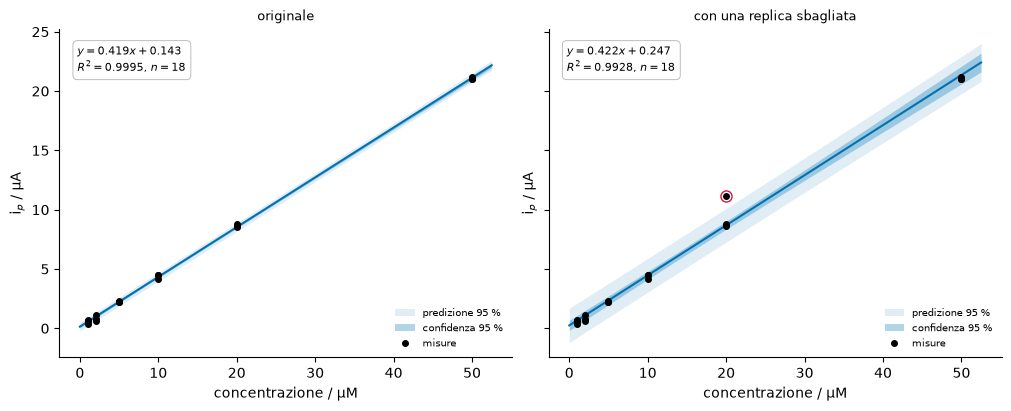

---
## 3. `curve_fit`: fit non lineare

Quando il modello non è una retta (saturazione, sigmoide, decadimento) si scrive
la funzione del modello e `curve_fit` trova i parametri che minimizzano gli scarti quadrati.
Restituisce i parametri (`popt`) e la matrice di covarianza (`pcov`): la radice della sua
diagonale è l'errore standard di ogni parametro.

Tre cose che fanno la differenza fra un fit che converge e uno che no:
1. `p0`: una stima iniziale ragionevole dei parametri (guardando il grafico);
2. `bounds`: limiti fisici (una costante di tempo non è negativa);
3. aver guardato i dati prima: un anomalo trascina qualsiasi fit.

In [ ]:
cin = pd.read_csv(DATI / "cinetica.csv")
t, c = cin["t_min"].to_numpy(), cin["conc_residua_%"].to_numpy()

def decadimento(t, C0, tau, plateau):
    """Decadimento esponenziale verso un plateau."""
    return C0 * np.exp(-t / tau) + plateau

popt, pcov = curve_fit(decadimento, t, c, p0=[80, 30, 10], bounds=([0, 0, 0], [200, 500, 100]))
perr = np.sqrt(np.diag(pcov))
for nome, v, e in zip(["C0", "tau", "plateau"], popt, perr):
    print(f"{nome:8s} = {v:7.2f} ± {e:.2f}")
print(f"tempo di dimezzamento = {popt[1] * np.log(2):.1f} min")

In [ ]:
tt = np.linspace(0, 120, 200)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(t, c, "o", ms=4, color="black", label="misure")
ax.plot(tt, decadimento(tt, *popt), "-", label=f"fit: τ = {popt[1]:.1f} ± {perr[1]:.1f} min")
ax.set_xlabel("tempo / min"); ax.set_ylabel("concentrazione residua / %"); ax.legend(frameon=False)
plt.show()

### Curva sigmoide (logistica a 4 parametri)

Il modello "a S" più usato quando una risposta sale da un plateau basso a uno alto al crescere
di una dose, una concentrazione, una temperatura…:

$$R(d) = R_{min} + \frac{R_{max} - R_{min}}{1 + (x_{50}/d)^{n}}$$

$x_{50}$ è il punto di metà salita (la dose che dà metà della risposta), $n$ la ripidità.
Si fitta sulla dose in scala originale, ma si guarda con l'asse x in scala log.

In [ ]:
dr = pd.read_csv(DATI / "dose_risposta.csv")
d, r = dr["dose_uM"].to_numpy(), dr["risposta_%"].to_numpy()

def sigmoide(d, Rmin, Rmax, x50, n):
    """Logistica a 4 parametri."""
    return Rmin + (Rmax - Rmin) / (1 + (x50 / d) ** n)

popt_s, pcov_s = curve_fit(sigmoide, d, r, p0=[0, 100, 10, 1], bounds=([-10, 50, 0.01, 0.2], [30, 150, 1000, 5]))
perr_s = np.sqrt(np.diag(pcov_s))
for nome, v, e in zip(["Rmin", "Rmax", "x50", "n"], popt_s, perr_s):
    print(f"{nome:6s} = {v:7.2f} ± {e:.2f}")

dd = np.logspace(-1.2, 3.2, 200)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(d, r, "o", ms=4, color="black", label="misure")
ax.plot(dd, sigmoide(dd, *popt_s), "-", label=f"sigmoide: $x_{{50}}$ = {popt_s[2]:.1f} ± {perr_s[2]:.1f} µM")
ax.set_xscale("log"); ax.set_xlabel("dose / µM"); ax.set_ylabel("risposta / %"); ax.legend(frameon=False)
plt.show()

---
## 4. Analisi dei residui: riconoscere un fit sbagliato che sembra buono

**Residuo** = misura − modello. Se il modello è giusto, i residui sono rumore: sparsi attorno
allo zero, senza struttura. Se mostrano una forma (una curva, una tendenza, un ventaglio
che si allarga), il modello è sbagliato, anche con R² = 0.99.

Esempio: fittiamo la cinetica con una retta. R² alto, fit "accettabile" a occhio. Poi
guardate i residui.

In [ ]:
reg_lin = stats.linregress(t, c)
res_lin = c - (reg_lin.slope * t + reg_lin.intercept)
res_exp = c - decadimento(t, *popt)

fig, axs = plt.subplots(2, 2, figsize=(9, 5.5), constrained_layout=True, sharex="col")
axs[0, 0].plot(t, c, "o", ms=4, color="black"); axs[0, 0].plot(tt, reg_lin.slope * tt + reg_lin.intercept, "-", color="crimson")
axs[0, 0].set_title(f"retta: R² = {reg_lin.rvalue**2:.3f}", fontsize=9); axs[0, 0].set_ylabel("conc. residua / %")
axs[0, 1].plot(t, c, "o", ms=4, color="black"); axs[0, 1].plot(tt, decadimento(tt, *popt), "-")
r2_exp = 1 - np.sum(res_exp ** 2) / np.sum((c - c.mean()) ** 2)
axs[0, 1].set_title(f"esponenziale: R² = {r2_exp:.3f}", fontsize=9)
for ax, res, col in [(axs[1, 0], res_lin, "crimson"), (axs[1, 1], res_exp, "#0072B2")]:
    ax.axhline(0, color="gray", lw=0.8)
    ax.plot(t, res, "o-", ms=4, color=col, lw=0.6)
    ax.set_xlabel("tempo / min")
axs[1, 0].set_ylabel("residuo / %")
axs[1, 0].set_title("residui con STRUTTURA: modello sbagliato", fontsize=9)
axs[1, 1].set_title("residui senza struttura", fontsize=9)
plt.show()

### Esercizio 6.2 (E3.2): fit non lineare con incertezze e residui (livello 2)

Sulla curva sigmoide (`dose_risposta.csv`):
1. fittate anche un modello sbagliato ma plausibile: la retta in `log10(dose)`
   (`stats.linregress(np.log10(d), r)`);
2. calcolate R² per entrambi (sigmoide e retta-log);
3. figura a due pannelli: sopra dati + le due curve (asse x log); sotto i residui dei due modelli;
4. stampate i parametri della sigmoide come `valore ± incertezza`, e scrivete in una riga di commento
   quale modello scegliete e perché (non per l'R²).

In [ ]:
# ESERCIZIO 6.2 (livello 2)
# 1. reg_log = linregress su log10(d)
# 2. residui e R² dei due modelli
# 3. figura 2 righe x 1 colonna, sharex
# 4. stampa e commento

# scrivi qui il tuo codice


**Output atteso**

```
R² sigmoide = 0.9974   R² retta-log = 0.9189
Rmin  =    6.77 ±  1.78
Rmax  =  100.95 ±  2.06
x50   =   14.02 ±  1.23
n     =    1.30 ±  0.14
```

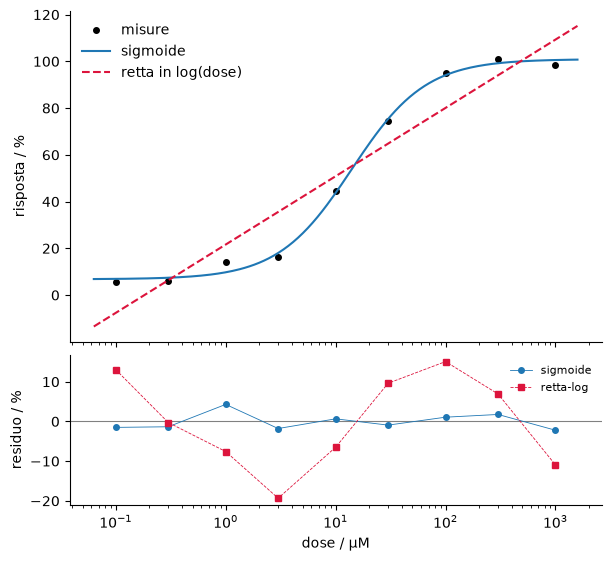

> Estensione facoltativa: stimate l'incertezza di $x_{50}$ anche per bootstrap (ricampionate
> le coppie (d, r) con reinserimento 500 volte, rifate il fit, prendete il 2.5° e 97.5°
> percentile). Confrontate con ± dalla matrice di covarianza.

---
## 5. Statistica di base: distribuzioni, t-test, ANOVA

Il dataset: una risposta misurata su 8 repliche per tre trattamenti (controllo, A, B).
La domanda: i trattamenti cambiano la risposta?

Prima di ogni test si guardano i dati (box plot con punti), e chiedersi se le assunzioni reggono
(normalità approssimativa entro gruppo, varianze simili). Con n = 8 i test di normalità
hanno poca potenza: il grafico vale più dello Shapiro.

In [ ]:
grp = pd.read_csv(DATI / "confronto_gruppi.csv")
gruppi = {g: grp.loc[grp["trattamento"] == g, "risposta"].to_numpy() for g in ["controllo", "trattamento_A", "trattamento_B"]}
print(grp.groupby("trattamento")["risposta"].agg(["count", "mean", "std"]).round(2))

for g, v in gruppi.items():
    W, p = stats.shapiro(v)
    print(f"Shapiro {g:14s}: W = {W:.3f}, p = {p:.3f}")

In [ ]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.boxplot(list(gruppi.values()), positions=range(3), widths=0.5, showfliers=False)
for k, v in enumerate(gruppi.values()):
    ax.plot(k + rng.normal(0, 0.05, v.size), v, "o", ms=4, color="crimson", alpha=0.7)
ax.set_xticks(range(3), list(gruppi)); ax.set_ylabel("risposta / u.a.")
plt.show()

### t-test per due gruppi

`ttest_ind` confronta due medie. Usate `equal_var=False` (t di Welch) come default: non
richiede varianze uguali e costa pochissimo in potenza quando lo sono.

In [ ]:
for g in ["trattamento_A", "trattamento_B"]:
    res = stats.ttest_ind(gruppi[g], gruppi["controllo"], equal_var=False)
    diff = gruppi[g].mean() - gruppi["controllo"].mean()
    d_cohen = diff / np.sqrt((gruppi[g].var(ddof=1) + gruppi["controllo"].var(ddof=1)) / 2)
    print(f"{g} vs controllo: diff = {diff:+.2f}, t = {res.statistic:.2f}, p = {res.pvalue:.4f}, d di Cohen = {d_cohen:.2f}")

### Cosa significa davvero un p-value

$p$ è la probabilità di osservare una differenza almeno così grande *se* i due gruppi
venissero dalla stessa popolazione. Non è la probabilità che l'ipotesi nulla sia vera, e
**non misura quanto è grande l'effetto**: con n enorme, un effetto irrilevante ha p minuscolo;
con n = 8, un effetto reale può avere p = 0.15.

Per questo accanto al p-value si riporta sempre la dimensione dell'effetto (la differenza
con il suo intervallo di confidenza, o il d di Cohen). Guardate il caso di A: differenza
di −0.4 con p ≈ 0.5. "Non significativo" non vuol dire "nessun effetto", vuol dire che non
abbiamo abbastanza dati per vederlo.

### ANOVA a una via, e poi confronti a coppie

Con tre o più gruppi non si fanno tre t-test: si fa un'ANOVA (c'è *qualche* differenza?)
e, se sì, i confronti post-hoc corretti (Tukey HSD) per dire *quali* gruppi differiscono.

In [ ]:
F, p = stats.f_oneway(*gruppi.values())
print(f"ANOVA a una via: F = {F:.2f}, p = {p:.2g}")

tukey = stats.tukey_hsd(*gruppi.values())
nomi = list(gruppi)
print("\nTukey HSD (coppie):")
for i in range(3):
    for j in range(i + 1, 3):
        lo, hi = tukey.confidence_interval().low[i, j], tukey.confidence_interval().high[i, j]
        print(f"  {nomi[i]:14s} - {nomi[j]:14s}: diff = {tukey.statistic[i, j]:+.2f}  IC95 [{lo:+.2f}, {hi:+.2f}]  p = {tukey.pvalue[i, j]:.4f}")

### Igiene statistica: confronti multipli e sovra-interpretazione

Se fate 20 test su dati puramente casuali, in media uno viene "significativo" al 5 %.
È aritmetica. Proviamo:

In [ ]:
rng = np.random.default_rng(1)
p_vals = [stats.ttest_ind(rng.normal(size=8), rng.normal(size=8)).pvalue for _ in range(20)]
print("p-value di 20 confronti fra gruppi IDENTICI (tutti rumore):")
print(np.round(sorted(p_vals), 3))
print(f"'significativi' (p < 0.05): {sum(p < 0.05 for p in p_vals)}   con Bonferroni (p < 0.05/20): {sum(p < 0.05/20 for p in p_vals)}")

Regole minime:
- Decidete prima quali confronti fare; non cercate "quello che viene significativo".
- Con più confronti, correggete (Bonferroni è conservativo ma semplice; Tukey per le coppie dopo ANOVA).
- Riportate effetto, intervallo di confidenza e n, non solo l'asterisco.
- Il test non sostituisce il grafico: se dal box plot non si vede niente, con n = 8 un p < 0.05 va preso con le pinze.

### Esercizio 6.3: confronto fra matrici, fatto bene (livello 2)

Con `misure_pulite.csv` di ieri (o il file grezzo pulito al volo con la stessa regola del
giorno 2): il rame ha concentrazione diversa nelle tre matrici?

Due trappole da evitare prima di lanciare qualsiasi test:

1. **Pseudo-repliche.** Ogni campione è stato misurato 2-3 volte. Le repliche dello stesso
   campione non sono osservazioni indipendenti: misurano lo stesso materiale, e si somigliano
   fra loro più che a un altro campione. Darle tutte all'ANOVA come se fossero campioni diversi
   gonfia $n$ e rende il p-value troppo piccolo. Prima si riduce a un valore per campione.
2. **Distribuzione asimmetrica.** Le concentrazioni sono positive, con coda a destra, e la loro
   dispersione cresce con la media (lognormali): proprio le condizioni in cui l'ANOVA soffre. Si
   lavora in log10: la media dei log è il log della *media geometrica*, e una differenza fra
   medie in log10 è un rapporto ($10^{\Delta}$: "il suolo ha 3 volte il rame della foglia").

Passi: log10 → media per campione → box plot con punti → ANOVA + Tukey sui log → differenze
riportate come rapporti con il loro IC → Kruskal-Wallis (`stats.kruskal`, non parametrico) come
controllo. Scrivete in un commento la conclusione in una frase, con effetto e intervallo, non solo p.

In [ ]:
# ESERCIZIO 6.3 (livello 2)
if Path("misure_pulite.csv").exists():
    misure = pd.read_csv("misure_pulite.csv")
else:   # pulizia al volo, con la stessa regola del giorno 2 (anomali: > 3 IQR in log10, per analita x matrice)
    misure = pd.read_csv(DATI / "misure_sporche.csv", sep=";", decimal=",", encoding="latin-1",
                         comment="#", na_values=["n.d."])
    misure = misure.rename(columns={"concentrazione (µg/L)": "conc_ug_L"}).dropna(subset=["conc_ug_L"]).drop_duplicates()
    lc = np.log10(misure["conc_ug_L"])
    g = lc.groupby([misure["analita"], misure["matrice"]])
    q1, q3 = g.transform(lambda s: s.quantile(0.25)), g.transform(lambda s: s.quantile(0.75))
    misure = misure[(lc >= q1 - 3 * (q3 - q1)) & (lc <= q3 + 3 * (q3 - q1))]
cu = misure[misure["analita"] == "Cu"].copy()
cu["log_conc"] = np.log10(cu["conc_ug_L"])
# 1. un valore per campione: cu.groupby(["campione", "matrice"])["log_conc"].mean().reset_index()
# 2. dizionario matrice -> array dei valori per campione; box plot con punti (asse y in log)
# 3. ANOVA + Tukey sui log10; differenze come rapporti 10**diff, con IC
# 4. stats.kruskal come controllo

# scrivi qui il tuo codice


**Output atteso**

```
90 misure di Cu -> 40 campioni indipendenti
{'foglia': 10, 'frutto': 15, 'suolo': 15} campioni per matrice
ANOVA sui log10: F = 97.4, p = 1.8e-15
  frutto / foglia: rapporto = 0.53  IC95 [0.40, 0.70]   p = 1.1e-05
  suolo / foglia: rapporto = 2.27  IC95 [1.71, 3.02]   p = 8e-08
  suolo / frutto: rapporto = 4.29  IC95 [3.32, 5.54]   p = 3.3e-15
Kruskal-Wallis: H = 32.4, p = 9.4e-08
```

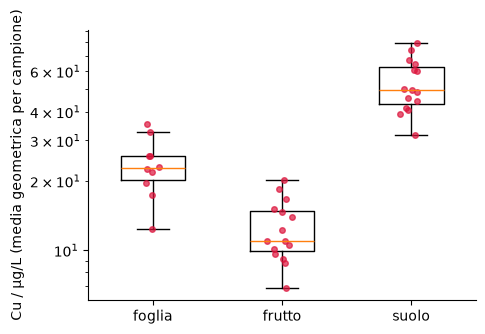

---
## Riepilogo del giorno 3

| Serve… | Funzione |
|---|---|
| retta con errori sui parametri | `stats.linregress` → `.slope, .stderr, .intercept, .intercept_stderr` |
| intervallo al 95 % | ± `stats.t.ppf(0.975, n-2)` × errore standard |
| bande di confidenza / predizione | formule con $s_{y/x}$ e $S_{xx}$ (funzione `bande_retta`) |
| report completo di una retta | `report_regressione` (Es. 6.1), e guardare il grafico: l'R² non avverte |
| fit non lineare | `curve_fit(f, x, y, p0=, bounds=)` → `np.sqrt(np.diag(pcov))` |
| il fit è giusto? | residui senza struttura, non R² |
| due gruppi | `stats.ttest_ind(a, b, equal_var=False)` + d di Cohen |
| tre o più gruppi | `stats.f_oneway` poi `stats.tukey_hsd`; controllo non parametrico `stats.kruskal` |
| repliche dello stesso campione | un valore per campione prima del test (niente pseudo-repliche) |
| concentrazioni (positive, asimmetriche) | test in log10, effetti come rapporti |
| tanti test | correggere, o meglio: decidere prima |

Domani: PCA e un modello predittivo, e come capire quando il risultato non vale niente.

---
*Riferimenti: Scientific Python Lectures (lectures.scientific-python.org), sezioni SciPy e
statistica (CC-BY 4.0); J. N. Miller & J. C. Miller, "Statistics and Chemometrics for
Analytical Chemistry" per le formule della taratura.*